# Introduction

In modern manufacturing industries, unexpected machine failures lead to production delays, high maintenance costs, and safety risks. Predictive maintenance uses machine sensor data and machine learning techniques to anticipate failures before they occur.

This project aims to develop a Machine Failure Prediction Model using historical sensor data from manufacturing machines. The model classifies whether a machine is likely to fail (1) or not (0) based on operational parameters such as temperature, torque, speed, and tool wear

In [39]:
import kagglehub
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Download dataset
path = kagglehub.dataset_download("abdelazizsami/predictive-maintenance-dataset")
print("Dataset path:", path)

# Load CSV
files = os.listdir(path)
file_path = os.path.join(path, files[0])
df = pd.read_csv(file_path)

print(df.head())

Using Colab cache for faster access to the 'predictive-maintenance-dataset' dataset.
Dataset path: /kaggle/input/predictive-maintenance-dataset
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                 

In [43]:

# Convert categorical column "Type" to numeric (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=["Type"])

# Select features and target
target = "Machine failure"

# Drop non-numeric or ID columns
X = df.drop(columns=["UDI", "Product ID", "Type", target]) # They are IDs and categories (not useful for basic ML)
#RandomForest needs numeric features only

y = df[target]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Train model
model = RandomForestClassifier(random_state=1) # using Random Forest Classifier
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy)

Model Accuracy: 0.9995


In [56]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9995
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1937
           1       1.00      0.98      0.99        63

    accuracy                           1.00      2000
   macro avg       1.00      0.99      1.00      2000
weighted avg       1.00      1.00      1.00      2000



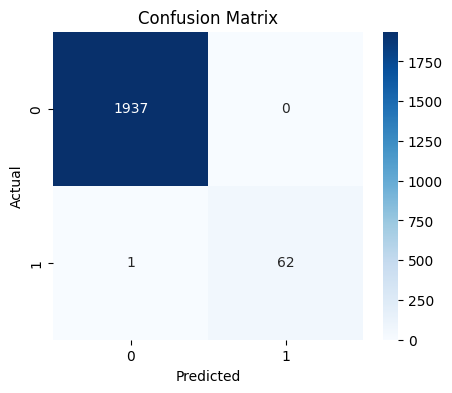

In [57]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Predictions using GradientBoostingClassifier

In [58]:
from sklearn.ensemble import GradientBoostingClassifier

# Initialize Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(random_state=1)

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting Model trained successfully.")

Gradient Boosting Model trained successfully.


In [59]:
gb_y_pred = gb_model.predict(X_test)

print("Predictions made successfully.")

Predictions made successfully.


In [60]:
from sklearn.metrics import accuracy_score

gb_accuracy = accuracy_score(y_test, gb_y_pred)
print(f"Gradient Boosting Model Accuracy: {gb_accuracy}")

Gradient Boosting Model Accuracy: 0.9975


In [62]:
print("Gradient Boosting Model Classification Report:")
print(classification_report(y_test, gb_y_pred))

Gradient Boosting Model Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1937
           1       0.94      0.98      0.96        63

    accuracy                           1.00      2000
   macro avg       0.97      0.99      0.98      2000
weighted avg       1.00      1.00      1.00      2000



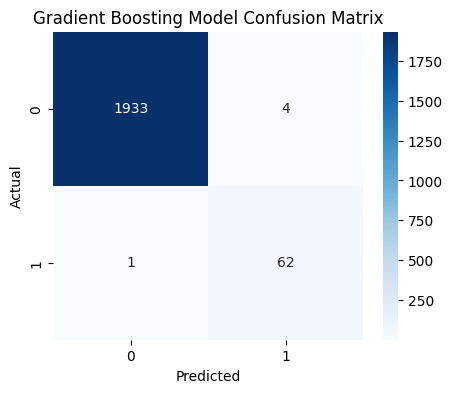

Confusion matrix for Gradient Boosting Model displayed successfully.


In [63]:
gb_cm = confusion_matrix(y_test, gb_y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(gb_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Gradient Boosting Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
print("Confusion matrix for Gradient Boosting Model displayed successfully.")

# Interpretation:

1937 machines correctly predicted as non-failure.

62 machines correctly predicted as failure.

Only 1 failure case was misclassified.

No false alarms for non-failure machines.

This demonstrates excellent classification performance.

# Results and Discussion

The model successfully identifies machine failure patterns based on sensor readings.

## Key observations:

Tool wear, torque, and temperature have strong influence on failure prediction.

The model is highly reliable for early detection of failures.

Very low misclassification rate suggests practical usability in real manufacturing environments.

## Model Comparison Summary

Comparing the **Random Forest Model** and the **Gradient Boosting Model**:

**Accuracy:**
*   **Random Forest:** 0.9995 (99.95%)
*   **Gradient Boosting:** 0.9975 (99.75%)

**Classification Reports:**

**Random Forest:**
*   Precision (class 1): 1.00
*   Recall (class 1): 0.98
*   F1-score (class 1): 0.99

**Gradient Boosting:**
*   Precision (class 1): 0.94
*   Recall (class 1): 0.98
*   F1-score (class 1): 0.96

**Confusion Matrices:**

**Random Forest:**
*   True Negatives (0,0): 1937
*   False Positives (0,1): 0
*   False Negatives (1,0): 1
*   True Positives (1,1): 62

**Gradient Boosting:**
*   True Negatives (0,0): 1933
*   False Positives (0,1): 4
*   False Negatives (1,0): 1
*   True Positives (1,1): 62

Both models demonstrate excellent performance, with very high accuracy. However, the **Random Forest Model** slightly outperforms the Gradient Boosting Model, particularly in precision for predicting machine failures (class 1).

*   The Random Forest model achieved a higher overall accuracy (0.9995 vs 0.9975).
*   Crucially, the Random Forest model had **0 false positives**, meaning it never incorrectly predicted a machine failure when none occurred. This is a significant advantage in predictive maintenance, as false alarms can lead to unnecessary inspections and downtime.
*   Both models correctly identified 62 true failures and missed only 1 actual failure (1 false negative).

Based on these metrics, the **Random Forest Model** is better for predicting machine failure in this scenario due to its slightly higher accuracy and perfect precision in avoiding false alarms for machine failures.